# Bitacoras onomásticas SEMEFO 1968-1982
# Análisis demográfico

In [2]:
import pandas as pd
from numpy import nan

import matplotlib.pyplot as plt
import seaborn as sns

def summary_top_series(s, n_values=5, sep=', ', **kwargs):
    s = s.value_counts(**kwargs).head(n_values)
    s = s.to_dict()
    s = sep.join([f"{k} ({v})" for k,v in s.items()])
    return s

colors = {'conocido':'#8dd3c7', #verde retoño
          'desconocido':'#fdb462', #naranja
          'Femenino':'#bc80bd', #magenta
          'Masculino':'#80b1d3', #azul
          'S-D':'#999999', #gris
          'Cadáver':'#ffffb3', #amarillo
          'Recién nacido':'#f560ac', #rosa
          'Feto':'#bebada', #lila
          'Miembros':'#b3de69', #verde amarillo
          'Restos óseos':'#fb8072' # rojo
         }
colors['Cadáver conocido'] = colors['conocido']
colors['Cadáver desconocido'] = colors['desconocido']

In [4]:
!pip install pickle5
import pickle5 as pickle

In [6]:
with open('data_clean/SEMEFO_BO_all.pkl', 'rb') as f:
    df = pickle.load(f)
df

AttributeError: Can't get attribute '_unpickle_block' on <module 'pandas._libs.internals' from '/home/esther/anaconda3/envs/CursoPandas2024/lib/python3.7/site-packages/pandas/_libs/internals.cpython-37m-x86_64-linux-gnu.so'>

In [5]:
df = pd.read_pickle('data_clean/SEMEFO_BO_all.pkl')
df['Bitacora_ingresos'] = df['Bitacora_ingresos'].apply(lambda s: s.replace('semefo_df_bo_',''))
df

ValueError: unsupported pickle protocol: 5

In [3]:
col_nom = ['Primer_apellido', 'Segundo_apellido', 'Nombres_propios']
for col in col_nom:
    mask = (df['Tipo_restos']!='Cadáver') & (df[col]!='S-D')
    df[col] = df[col].mask(mask, other='Reservado')

mask = (df[col_nom]=='Reservado').any(axis=1)
df['Nombre_completo_transcrito'] = df['Nombre_completo_transcrito'].mask(mask, other='Reservado')

key_col = ['Nombre_completo_transcrito', 'Primer_apellido', 'Segundo_apellido', 'Nombres_propios', 'Tipo_restos']
data = df[['ID']+key_col]
data

,ID,Nombre_completo_transcrito,Primer_apellido,Segundo_apellido,Nombres_propios,Tipo_restos
0,BO_1968_00001,acosta ortega teresa,acosta,ortega,teresa,Cadáver
1,BO_1968_00002,avila de cuestas catalina,avila,de cuestas,catalina,Cadáver
2,BO_1968_00003,arzate paredes juan,arzate,paredes,juan,Cadáver
3,BO_1968_00004,alvarez martinez isaac,alvarez,martinez,isaac,Cadáver
4,BO_1968_00005,arellano viuda de campos ma.,arellano,viuda de campos,ma.,Cadáver
...,...,...,...,...,...,...
96839,BO_1982_07489,placenta,S-D,S-D,S-D,Miembros
96840,BO_1982_07490,5 dedos del pie derecho de desconocido,S-D,S-D,S-D,Miembros
96841,BO_1982_07491,dedo de desconocido,S-D,S-D,S-D,Miembros
96842,BO_1982_07492,4 dedos de desconocido,S-D,S-D,S-D,Miembros


In [4]:
data.to_csv('data_clean/SEMEFO_BO_all_NombresReservados.csv', index=False)

In [5]:
df.columns

Index(['ID', 'Numero_progresivo_transcrito', 'Nombre_completo_transcrito',
       'Primer_apellido', 'Segundo_apellido', 'Nombres_propios',
       'Fecha_transcrito', 'Fecha_estandar', 'Fecha_añomes', 'Fecha_diasemana',
       'Sexo', 'Edad_transcrito', 'Edad_estandar', 'Edad_rango',
       'Expediente_SEMEFO_transcrito', 'Procedencia_transcrito',
       'Procedencia_estandar', 'Procedencia_direccion', 'Procedencia_alcaldia',
       'Numero_acta_transcrito', 'Procedencia_acta', 'Diagnostico_transcrito',
       'Diagnostico_estandar', 'Diagnostico_extendido', 'Tipo_restos',
       'Conocido_desconocido', 'Bitacora_ingresos', 'Pagina_PDF',
       'Foja_transcrito', 'Observaciones'],
      dtype='object')

## Missing

In [6]:
pd.DataFrame( df['Bitacora_ingresos'].value_counts().sort_index())

,count
Bitacora_ingresos,
1968,4719
1969,5052
1970,5303
1971,5524
1972,5768
1973,6471
1974,5731
1975,6861
1976,6907


In [7]:
col_trans = [col for col in df.columns if 'transcrito' in col]
col_trans

data = df[col_trans]
data['Año'] = df['Bitacora_ingresos'].replace({'semefo_df_':''}, regex=True)
data = data.replace({'S-D':nan, 's-d':nan})

/tmp/ipykernel_4496/2440187126.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['Año'] = df['Bitacora_ingresos'].replace({'semefo_df_':''}, regex=True)


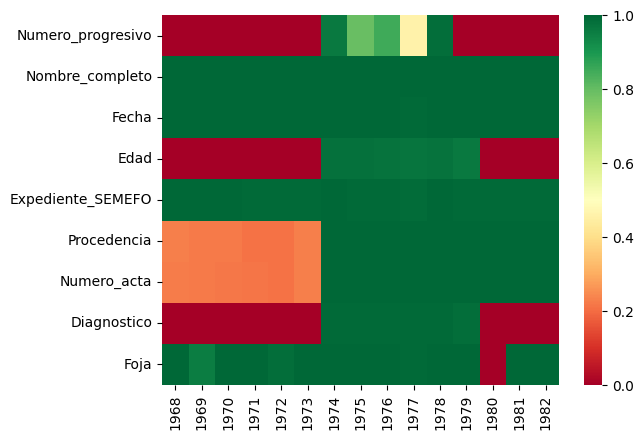

In [8]:
data_miss = data.groupby('Año').agg({col:lambda s: s.notna().sum() / len(s) for col in col_trans })
data_miss.index = [i.replace('semefo_df_bo_','') for i in data_miss.index]
data_miss.columns = [i.replace('_transcrito','') for i in data_miss.columns]
#display( data_miss )
sns.heatmap(data_miss.transpose(), cmap='RdYlGn')
plt.show()

## Tipo de restos

,Frecuencia,Porcentaje
Tipo_restos,,
Cadáver,91254,94.227830
Feto,2844,2.936682
Miembros,2065,2.132295
Recién nacido,633,0.653629
Restos óseos,48,0.049564


<Axes: >

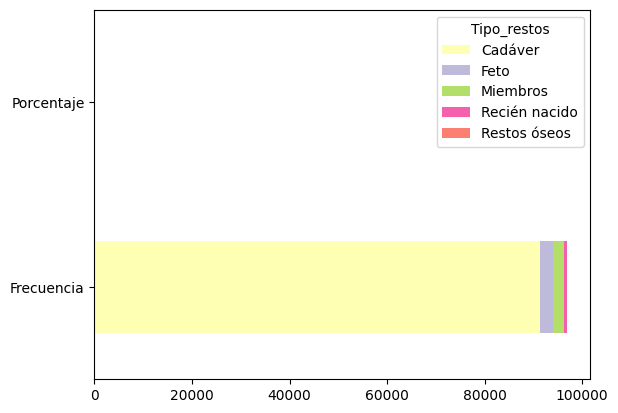

In [9]:
data = df['Tipo_restos'].value_counts()
data = pd.DataFrame(data)
data['mean'] = df['Tipo_restos'].value_counts(normalize=True)*100
data.columns = ['Frecuencia','Porcentaje']
display(data)
data.transpose().plot.barh(stacked=True, color=colors)

In [10]:
data = pd.pivot_table(df, index='Tipo_restos', columns=['Conocido_desconocido','Sexo'], aggfunc="size")
data

Conocido_desconocido      S-D               conocido                 \
Sexo                 Femenino Masculino S-D Femenino Masculino  S-D   
Tipo_restos                                                           
Cadáver                     0         0  19    17923     58337  496   
Recién nacido               0         0   0        8        23    0   
Feto                        0         0   0        6         9   16   
Miembros                    0         0   0      361      1405   29   
Restos óseos                0         0   0        0         0    0   

Conocido_desconocido desconocido                  
Sexo                    Femenino Masculino   S-D  
Tipo_restos                                       
Cadáver                     1580     12845    54  
Recién nacido                243       356     3  
Feto                         456       653  1704  
Miembros                      23       106   141  
Restos óseos                   1         7    40

In [11]:
def join_restos(row):
    if row[0] in ['Miembros','Restos óseos']:
        return 'Miembros'
    if row[0]!='Cadáver':
        return row[0]
    else: return row[0]+' '+row[1]

cat_type = ['Cadáver conocido', 'Cadáver desconocido', 'Recién nacido', 'Feto', 'Miembros']
cat_type = pd.CategoricalDtype(categories=cat_type, ordered=True)

df['Tipo_restos_ext'] = df[['Tipo_restos','Conocido_desconocido']].apply(join_restos, axis=1).astype(cat_type)
df['Tipo_restos_ext'].value_counts(dropna=False)

Tipo_restos_ext
Cadáver conocido       76756
Cadáver desconocido    14479
Feto                    2844
Miembros                2113
Recién nacido            633
NaN                       19
Name: count, dtype: int64

In [12]:
df['Tipo_restos_ext'].value_counts(dropna=False, normalize=True).round(4)

Tipo_restos_ext
Cadáver conocido       0.7926
Cadáver desconocido    0.1495
Feto                   0.0294
Miembros               0.0218
Recién nacido          0.0065
NaN                    0.0002
Name: proportion, dtype: float64

In [13]:
df[['Tipo_restos_ext','Sexo']].value_counts(normalize=True) \
  .reset_index().sort_values(by='Tipo_restos_ext').round(3)

,Tipo_restos_ext,Sexo,proportion
0,Cadáver conocido,Masculino,0.602
1,Cadáver conocido,Femenino,0.185
7,Cadáver conocido,S-D,0.005
2,Cadáver desconocido,Masculino,0.133
4,Cadáver desconocido,Femenino,0.016
13,Cadáver desconocido,S-D,0.001
10,Recién nacido,Masculino,0.004
11,Recién nacido,Femenino,0.003
14,Recién nacido,S-D,0.000
3,Feto,S-D,0.018


,Frecuencia,Porcentaje
Tipo_restos_ext,,
Cadáver conocido,76756,79.272915
Cadáver desconocido,14479,14.953783
Feto,2844,2.937258
Miembros,2113,2.182288
Recién nacido,633,0.653757


<Axes: >

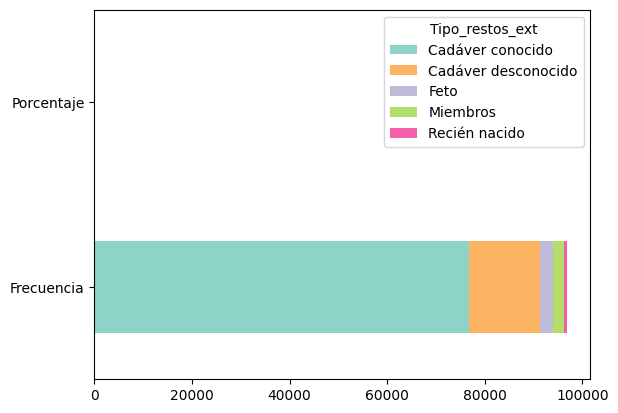

In [14]:
data = df['Tipo_restos_ext'].value_counts()
data = pd.DataFrame(data)
data['mean'] = df['Tipo_restos_ext'].value_counts(normalize=True)*100
data.columns = ['Frecuencia','Porcentaje']
display(data)
data.transpose().plot.barh(stacked=True, color=colors)

In [15]:
data = pd.pivot_table(df, index='Tipo_restos_ext', columns='Sexo', aggfunc="size")
data.divide(data.sum(axis=1), axis=0)*100

Sexo,Femenino,Masculino,S-D
Tipo_restos_ext,,,
Cadáver conocido,23.350618,76.003179,0.646204
Cadáver desconocido,10.912356,88.714690,0.372954
Recién nacido,39.652449,59.873618,0.473934
Feto,16.244726,23.277075,60.478200
Miembros,18.220540,71.840984,9.938476


In [16]:
data = pd.pivot_table(df, index='Tipo_restos_ext', columns='Bitacora_ingresos', aggfunc="size")
data / data.sum() * 100
#data.transpose().plot.barh(stacked=True, color=colors)

Bitacora_ingresos,1968,1969,1970,1971,1972,1973,1974,1975,1976,1977,1978,1979,1980,1981,1982
Tipo_restos_ext,,,,,,,,,,,,,,,
Cadáver conocido,77.156177,77.830562,77.861588,78.403331,78.172677,76.618761,77.124411,80.221542,79.496090,79.367744,79.899146,78.796408,81.848012,82.029099,81.289203
Cadáver desconocido,15.977961,16.152019,15.425231,15.025344,15.291262,15.824448,15.267842,13.438274,15.117289,14.715345,14.820003,15.587723,14.122588,13.684624,14.960630
Recién nacido,0.720492,0.692795,0.999434,0.814627,0.953537,1.282646,0.907346,0.553855,0.115841,0.657435,0.616333,0.442300,0.380627,0.393236,0.627252
Feto,4.852723,3.661916,4.016594,4.091238,3.432732,4.265183,4.309894,3.293980,3.214596,2.531823,2.409301,1.997051,1.653760,1.415651,1.147738
Miembros,1.292647,1.662708,1.697153,1.665460,2.149792,2.008963,2.390508,2.492348,2.056183,2.727654,2.255218,3.176518,1.995012,2.477389,1.975177


## Edad y sexo

(91887, 31)

Sexo,Femenino,Masculino,S-D
Edad_rango,,,
"(-1.0, 0.0]",760,1054,5
"(0.0, 4.0]",787,1172,0
"(4.0, 9.0]",464,928,1
"(9.0, 14.0]",320,902,0
"(14.0, 19.0]",607,1806,1
"(19.0, 24.0]",628,3134,0
"(24.0, 29.0]",589,3192,0
"(29.0, 34.0]",451,2557,0
"(34.0, 39.0]",477,2718,1


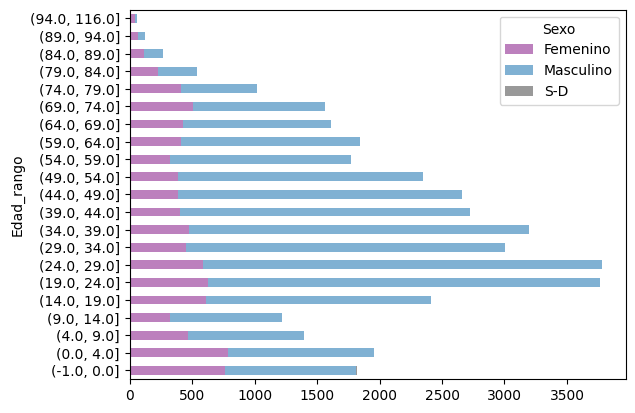

In [17]:
data = df[df['Tipo_restos'].isin(['Cadáver','Recién nacido'])]
display(data.shape)
data = pd.pivot_table(data, index='Edad_rango', columns='Sexo', aggfunc="size")
data.plot.barh(stacked=True, color=colors)
#plt.savefig('Sexo_EdadRango.svg')
data

<Axes: xlabel='Bitacora_ingresos'>

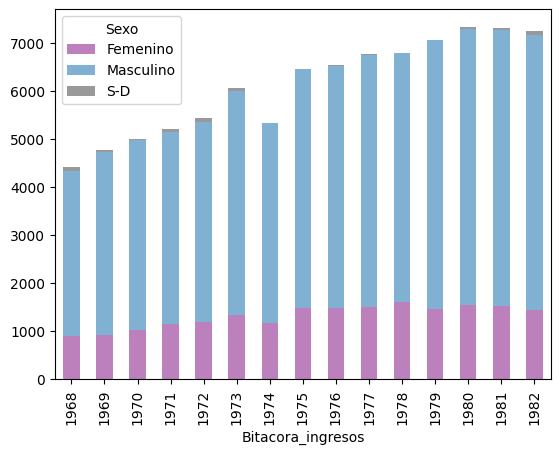

In [18]:
data = df[df['Tipo_restos'].isin(['Cadáver','Recién nacido'])]
data = pd.pivot_table(data, index='Sexo', columns='Bitacora_ingresos', aggfunc="size")
data.transpose().plot.bar(stacked=True, color=colors)

## Procedencia y diagnóstico

## Fecha

<Axes: xlabel='Bitacora_ingresos'>

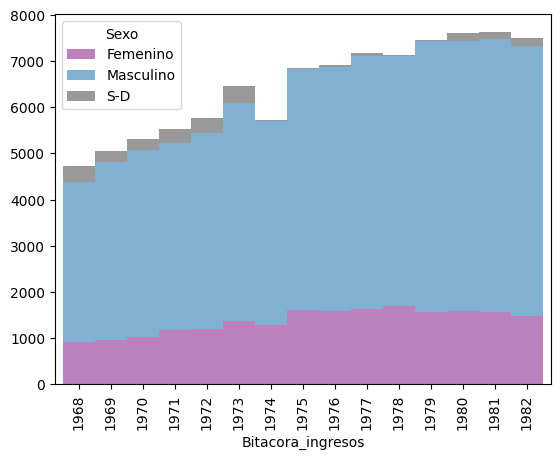

In [19]:
data = pd.pivot_table(df, index='Bitacora_ingresos', columns='Sexo', aggfunc="size")
data.plot.bar(stacked=True, width=1.0, color=colors)

<Axes: xlabel='Bitacora_ingresos'>

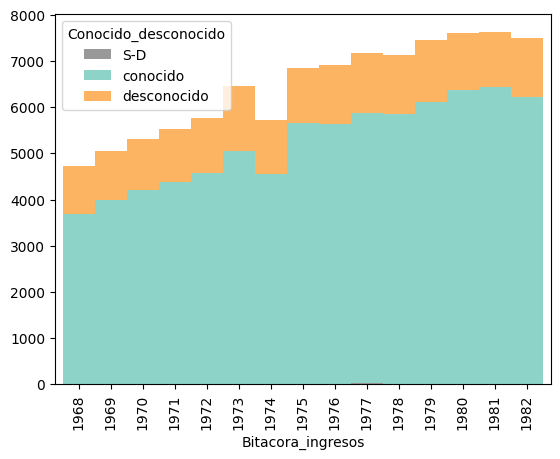

In [20]:
data = pd.pivot_table(df, index='Bitacora_ingresos', columns='Conocido_desconocido', aggfunc="size")
data.plot.bar(stacked=True, width=1.0, color=colors)

In [21]:
df.columns

Index(['ID', 'Numero_progresivo_transcrito', 'Nombre_completo_transcrito',
       'Primer_apellido', 'Segundo_apellido', 'Nombres_propios',
       'Fecha_transcrito', 'Fecha_estandar', 'Fecha_añomes', 'Fecha_diasemana',
       'Sexo', 'Edad_transcrito', 'Edad_estandar', 'Edad_rango',
       'Expediente_SEMEFO_transcrito', 'Procedencia_transcrito',
       'Procedencia_estandar', 'Procedencia_direccion', 'Procedencia_alcaldia',
       'Numero_acta_transcrito', 'Procedencia_acta', 'Diagnostico_transcrito',
       'Diagnostico_estandar', 'Diagnostico_extendido', 'Tipo_restos',
       'Conocido_desconocido', 'Bitacora_ingresos', 'Pagina_PDF',
       'Foja_transcrito', 'Observaciones', 'Tipo_restos_ext'],
      dtype='object')